# Aritmética de la convolución: la guía de Dumoulin y Visin

Las redes de este módulo usan casi siempre la misma receta: `Conv2d` con un kernel de 3 × 3 y relleno 1, seguida de un `MaxPool2d(2)`. Con eso, una imagen de 32 × 32 pasa a 16 × 16, después a 8 × 8 y después a 4 × 4, y la primera capa lineal, justo después de `Flatten`, recibe 128 · 4 · 4 = 2048 números. ¿Por qué relleno 1? ¿Qué pasa con una imagen de 30 × 30, o con un kernel de 4, o con paso 2? Cada una de esas preguntas tiene una respuesta exacta, y una cuenta mal hecha termina en el error de formas más común de PyTorch.

Entre las lecturas del curso para este tema está [*A guide to convolution arithmetic for deep learning*](https://arxiv.org/abs/1603.07285), de Vincent Dumoulin y Francesco Visin (2016, revisada en 2018). Es una guía corta que deduce, una por una, 15 relaciones (*relationships*) entre el tamaño de la entrada, el del kernel, el relleno, el paso y el tamaño de la salida: para la convolución, el *pooling*, la convolución transpuesta y la convolución dilatada. Este notebook sigue sus capítulos en el mismo orden y comprueba cada relación contra PyTorch, no con un ejemplo sino con miles de combinaciones. En el camino lo complementamos con los [apuntes de CS231n sobre redes convolucionales](https://cs231n.github.io/convolutional-networks/), otra lectura del curso. Cada afirmación que viene de una fuente lleva su link, y la sección **Fuentes**, al final, reúne las citas textuales.

- Reproduce número por número las figuras del capítulo 1 del artículo.
- Escribe las relaciones 1 a 6 como funciones, las comprueba contra `nn.Conv2d` y dibuja cómo se desliza el kernel en cada caso.
- Muestra qué se pierde con la división entera: entradas distintas que dan la misma salida y píxeles que el kernel nunca toca.
- Hace lo mismo con el *pooling* (relación 7).
- Arma la convolución como una matriz rala $C$ y comprueba que la convolución transpuesta es multiplicar por $C^\top$, lo mismo que calcula `backward()`.
- Comprueba las relaciones 8 a 14 de la convolución transpuesta y explica para qué existe `output_padding`.
- Cierra con la convolución dilatada (relación 15) y con la tabla de tamaños de las CNN del módulo.

No usa ningún conjunto de datos. Tarda alrededor de un minuto en una CPU, casi todo en las grillas de comprobación.

**Contenido**

1. Preparación
2. Las figuras del capítulo 1, número por número
3. Varios canales y la forma de los pesos
4. Sin relleno y con paso 1 (relación 1)
5. Relleno arbitrario, *half* y *full* (relaciones 2 a 4)
6. Pasos mayores que 1 (relaciones 5 y 6)
7. Lo que se come la división entera
8. *Pooling* (relación 7)
9. La convolución como una matriz
10. La convolución transpuesta (relaciones 8 a 14)
11. Convolución dilatada (relación 15)
12. Los tamaños de las CNN del módulo
13. Resumen y ejercicios

## 1. Preparación

Solo hacen falta PyTorch y matplotlib. Las funciones de dibujo se definen más abajo, cuando se usan por primera vez.

In [1]:
import itertools
import warnings

import torch
from torch import nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 2. Las figuras del capítulo 1, número por número

El capítulo 1 del artículo presenta la convolución discreta con un ejemplo: un kernel de 3 × 3 que se desliza sobre una entrada de 5 × 5. En cada posición se multiplica cada número del kernel por el número de la entrada que tiene debajo, y se suman los nueve productos; esa suma es el valor de la salida en esa posición ([sección 1.1](https://arxiv.org/abs/1603.07285), figura 1.1, p. 7). Copiamos la entrada y el kernel de la figura:

In [2]:
entrada = torch.tensor([[3, 3, 2, 1, 0],
                        [0, 0, 1, 3, 1],
                        [3, 1, 2, 2, 3],
                        [2, 0, 0, 2, 2],
                        [2, 0, 0, 0, 1]], dtype=torch.float32)
kernel = torch.tensor([[0, 1, 2],
                       [2, 2, 0],
                       [0, 1, 2]], dtype=torch.float32)

# F.conv2d espera [lote, canales, alto, ancho]; con [None, None] agregamos las dos primeras
salida = F.conv2d(entrada[None, None], kernel[None, None])[0, 0]
print(salida)

figura_1_1 = torch.tensor([[12., 12., 17.], [10., 17., 19.], [9., 6., 14.]])
print("¿Igual a la figura 1.1?", torch.equal(salida, figura_1_1))

tensor([[12., 12., 17.],
        [10., 17., 19.],
        [ 9.,  6., 14.]])
¿Igual a la figura 1.1? True


La primera salida, a mano: el kernel encima del bloque de 3 × 3 de arriba a la izquierda.

In [3]:
bloque = entrada[0:3, 0:3]
print(bloque)
print("productos sumados:", (bloque * kernel).sum().item())

tensor([[3., 3., 2.],
        [0., 0., 1.],
        [3., 1., 2.]])
productos sumados: 12.0


$3 \cdot 0 + 3 \cdot 1 + 2 \cdot 2 + 0 \cdot 2 + 0 \cdot 2 + 1 \cdot 0 + 3 \cdot 0 + 1 \cdot 1 + 2 \cdot 2 = 12$, el primer número de la figura.

Un detalle de nombres. En procesamiento de señales, la convolución da vuelta el kernel antes de deslizarlo; sin darlo vuelta, la operación se llama **correlación cruzada**. El artículo avisa en una nota al pie que las dos se vuelven intercambiables cuando el kernel se aprende, y que por simplicidad usa el nombre convolución para ambas ([sección 1.1, nota 2](https://arxiv.org/abs/1603.07285), p. 8). La documentación de [`nn.Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) dice lo mismo de otra forma: el operador que usa es la correlación cruzada. La figura 1.1 también es una correlación cruzada, y por eso calza con PyTorch sin dar vuelta nada. Si damos vuelta el kernel, el resultado cambia:

In [4]:
volteado = kernel.flip(0, 1)            # gira el kernel 180 grados
print(F.conv2d(entrada[None, None], volteado[None, None])[0, 0])

tensor([[18., 20., 19.],
        [10.,  9., 17.],
        [11.,  8., 14.]])


Son otros números. Como la red aprende los pesos, le da lo mismo: si la tarea pidiera el kernel dado vuelta, aprendería ese. Lo que importa es no mezclar las dos convenciones al comparar con un libro de señales, y lo vamos a necesitar en la sección 10.

La figura 1.2 usa la misma entrada con relleno de ceros de 1 y paso 2, y las figuras 1.5 y 1.6 aplican *pooling* promedio y máximo de 3 × 3 con paso 1:

In [5]:
figura_1_2 = torch.tensor([[6., 17., 3.], [8., 17., 13.], [6., 4., 4.]])
figura_1_5 = torch.tensor([[1.7, 1.7, 1.7], [1.0, 1.2, 1.8], [1.1, 0.8, 1.3]])
figura_1_6 = torch.tensor([[3., 3., 3.], [3., 3., 3.], [3., 2., 3.]])

x = entrada[None, None]
con_relleno_y_paso = F.conv2d(x, kernel[None, None], stride=2, padding=1)[0, 0]
promedio = F.avg_pool2d(x, kernel_size=3, stride=1)[0, 0]
maximo = F.max_pool2d(x, kernel_size=3, stride=1)[0, 0]

print("figura 1.2:", torch.equal(con_relleno_y_paso, figura_1_2))
print("figura 1.5:", torch.equal(promedio.round(decimals=1), figura_1_5), "  (la figura redondea a un decimal)")
print("figura 1.6:", torch.equal(maximo, figura_1_6))
print()
print(promedio)

figura 1.2: True
figura 1.5: True   (la figura redondea a un decimal)
figura 1.6: True

tensor([[1.6667, 1.6667, 1.6667],
        [1.0000, 1.2222, 1.7778],
        [1.1111, 0.7778, 1.3333]])


Las cuatro figuras del capítulo salen idénticas con las funciones de PyTorch. La figura 1.5 muestra los promedios con un decimal: 1.6667 aparece como 1.7.

## 3. Varios canales y la forma de los pesos

Una imagen en color tiene tres canales y una capa convolucional produce varios mapas de características. El artículo lo explica con la figura 1.3: dos mapas de entrada y tres de salida. Para cada mapa de salida hay un kernel por cada mapa de entrada; cada mapa de entrada se convoluciona con su kernel y los resultados se suman elemento a elemento ([sección 1.1](https://arxiv.org/abs/1603.07285), p. 8). En total son 3 × 2 kernels de 3 × 3. Lo comprobamos sumando a mano:

In [6]:
capa = nn.Conv2d(in_channels=2, out_channels=3, kernel_size=3)
x = torch.randn(1, 2, 5, 5)

print("forma de los pesos:", tuple(capa.weight.shape), "  forma del sesgo:", tuple(capa.bias.shape))

a_mano = torch.zeros(1, 3, 3, 3)
for salida_j in range(3):
    for entrada_c in range(2):
        w = capa.weight[salida_j, entrada_c][None, None]        # un kernel de 3 x 3
        a_mano[0, salida_j] += F.conv2d(x[:, entrada_c:entrada_c + 1], w)[0, 0]
    a_mano[0, salida_j] += capa.bias[salida_j]

print("¿Igual a nn.Conv2d?", torch.allclose(a_mano, capa(x), atol=1e-6))

forma de los pesos: (3, 2, 3, 3)   forma del sesgo: (3,)
¿Igual a nn.Conv2d? True


Los pesos de `nn.Conv2d` tienen forma `[salidas, entradas, alto, ancho]`: aquí `[3, 2, 3, 3]`. El artículo dice que la colección de kernels tiene la forma de "alguna permutación" de $(n, m, k_1, k_2)$, con $n$ mapas de salida y $m$ de entrada ([sección 1.1](https://arxiv.org/abs/1603.07285), p. 8). La palabra permutación no es un descuido: cada librería elige un orden, y dentro de PyTorch la convolución transpuesta usa el otro (sección 10).

La cantidad de parámetros, 3 · 2 · 3 · 3 + 3 = 57, no depende del tamaño de la imagen. La misma capa se aplica a una entrada de 5 × 5 o de 50 × 50; lo que cambia es el tamaño de la salida:

In [7]:
print("parámetros:", sum(p.numel() for p in capa.parameters()))
for lado in [5, 12, 50]:
    print(f"entrada {lado:2d} x {lado:2d}  ->  salida {tuple(capa(torch.randn(1, 2, lado, lado)).shape[-2:])}")

parámetros: 57
entrada  5 x  5  ->  salida (3, 3)
entrada 12 x 12  ->  salida (10, 10)
entrada 50 x 50  ->  salida (48, 48)


Eso es justo lo que motiva el artículo. Una capa lineal tiene un tamaño de salida fijo, que no depende de la entrada. En una capa convolucional, en cambio, la forma de la salida depende de la forma de la entrada y de la elección del kernel, el relleno y el paso, y la relación entre todo eso "no es trivial de inferir" ([capítulo 1](https://arxiv.org/abs/1603.07285), p. 5). El resto del notebook la deduce.

## 4. Sin relleno y con paso 1 (relación 1)

El capítulo 2 analiza un solo eje, porque las propiedades no interactúan entre ejes: el kernel, el paso y el relleno de un eje solo afectan el tamaño de salida de ese eje ([capítulo 2](https://arxiv.org/abs/1603.07285), p. 12). Escribimos $i$ para el tamaño de la entrada, $k$ para el del kernel, $s$ para el paso (*stride*), $p$ para el relleno (*padding*) y $o$ para el tamaño de la salida, como el artículo.

El caso más simple: $s = 1$ y $p = 0$. El tamaño de la salida es la cantidad de posiciones donde cabe el kernel. Empieza pegado a la izquierda y avanza de a uno hasta tocar el borde derecho: da $i - k$ pasos, y con la posición inicial son $i - k + 1$ posiciones. Esa es la **relación 1** ([sección 2.1](https://arxiv.org/abs/1603.07285), p. 13):

$$o = (i - k) + 1$$

La figura 2.1 del artículo muestra $i = 4$ y $k = 3$, que dan una salida de 2 × 2. Dibujamos las cuatro posiciones del kernel. Cada panel está en el lugar de la salida que produce:

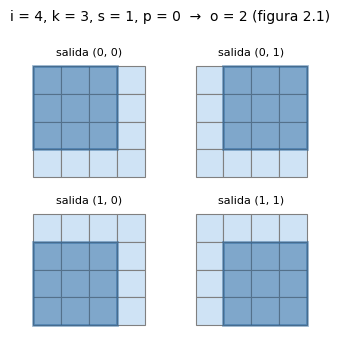

In [8]:
AZUL, AZUL_OSCURO, GRIS, ROJO, NARANJA = "#cfe3f5", "#1f5f99", "#eeeeee", "#f4a6a6", "#f7c98b"


def tam_conv(i, k, s=1, p=0, d=1):
    """Relación 15 del artículo; con d = 1 es la relación 6, y con p = 0 y s = 1, la relación 1."""
    return (i + 2 * p - k - (k - 1) * (d - 1)) // s + 1


def dibujar_grilla(eje, n, p, i, colores=None):
    """Una grilla de n x n celdas; las del borde de ancho p son relleno (gris, borde punteado)."""
    for fila in range(n):
        for col in range(n):
            relleno = fila < p or fila >= p + i or col < p or col >= p + i
            color = colores[fila][col] if colores else (GRIS if relleno else AZUL)
            eje.add_patch(Rectangle((col, n - 1 - fila), 1, 1, facecolor=color, edgecolor="gray",
                                    linewidth=0.8, linestyle="--" if relleno else "-"))
    eje.set_xlim(-0.1, n + 0.1)
    eje.set_ylim(-0.1, n + 0.1)
    eje.set_aspect("equal")
    eje.axis("off")


def dibujar_posiciones(i, k, s=1, p=0, titulo=""):
    """Un panel por cada posición del kernel, ubicado donde queda su salida."""
    o, n = tam_conv(i, k, s, p), i + 2 * p
    fig, ejes = plt.subplots(o, o, figsize=(1.7 * o, 1.7 * o), squeeze=False)
    for f in range(o):
        for c in range(o):
            eje = ejes[f][c]
            dibujar_grilla(eje, n, p, i)
            eje.add_patch(Rectangle((c * s, n - f * s - k), k, k, facecolor=AZUL_OSCURO, alpha=0.45,
                                    edgecolor=AZUL_OSCURO, linewidth=2))
            eje.set_title(f"salida ({f}, {c})", fontsize=8)
    fig.suptitle(titulo, fontsize=10)
    plt.tight_layout()
    plt.show()


dibujar_posiciones(4, 3, titulo="i = 4, k = 3, s = 1, p = 0  →  o = 2 (figura 2.1)")

Comprobamos la relación 1 contra `nn.Conv2d` en todas las combinaciones con entradas de 1 a 30 y kernels de 1 a 7 que tengan sentido ($k \le i$). Para medir la forma de la salida no hace falta calcular nada de verdad: alcanza con pasar ceros.

In [9]:
def tam_pytorch(i, k, s=1, p=0, d=1):
    """Lado de la salida de F.conv2d para una entrada de i x i y un kernel de k x k."""
    return F.conv2d(torch.zeros(1, 1, i, i), torch.zeros(1, 1, k, k), stride=s, padding=p, dilation=d).shape[-1]


def relacion_1(i, k):
    return (i - k) + 1


casos = [(i, k) for i in range(1, 31) for k in range(1, 8) if k <= i]
coinciden = sum(relacion_1(i, k) == tam_pytorch(i, k) for i, k in casos)
print(f"relación 1: {len(casos)} combinaciones, coinciden {coinciden}")

relación 1: 189 combinaciones, coinciden 189


## 5. Relleno arbitrario, *half* y *full* (relaciones 2 a 4)

Rellenar con $p$ ceros a cada lado convierte una entrada de tamaño $i$ en una de tamaño $i + 2p$, y la relación 1 se aplica a esa entrada agrandada. Es la **relación 2** ([sección 2.2](https://arxiv.org/abs/1603.07285), p. 13):

$$o = (i - k) + 2p + 1$$

Dos rellenos se usan tanto que tienen nombre:

- **Relleno *half* o *same*** (**relación 3**): con $k$ impar, $k = 2n + 1$, y $p = \lfloor k/2 \rfloor = n$, la salida mide lo mismo que la entrada, $o = i$ ([sección 2.2.1](https://arxiv.org/abs/1603.07285)). Es el relleno 1 de los kernels de 3 × 3 del módulo. CS231n da la misma regla con su notación: $P = (F - 1)/2$ con paso 1 conserva el tamaño ([*Convolutional Layer*](https://cs231n.github.io/convolutional-networks/#conv), "Use of zero-padding").
- **Relleno *full*** (**relación 4**): con $p = k - 1$, la salida crece, $o = i + (k - 1)$, porque se cuenta cada superposición posible del kernel con la entrada, completa o parcial ([sección 2.2.2](https://arxiv.org/abs/1603.07285), pp. 13 y 15).

Las tres, comprobadas:

In [10]:
def relacion_2(i, k, p):
    return (i - k) + 2 * p + 1


casos_2 = [(i, k, p) for i in range(1, 31) for k in range(1, 8) for p in range(0, 5) if k <= i + 2 * p]
print(f"relación 2: {len(casos_2)} combinaciones, coinciden "
      f"{sum(relacion_2(i, k, p) == tam_pytorch(i, k, p=p) for i, k, p in casos_2)}")

impares = [(i, k) for i in range(1, 31) for k in [1, 3, 5, 7]]
print(f"relación 3 (k impar, p = k // 2): {len(impares)} combinaciones, salida igual a la entrada en "
      f"{sum(tam_pytorch(i, k, p=k // 2) == i for i, k in impares)}")

completos = [(i, k) for i in range(1, 31) for k in range(1, 8)]
print(f"relación 4 (p = k - 1): {len(completos)} combinaciones, coinciden "
      f"{sum(tam_pytorch(i, k, p=k - 1) == i + (k - 1) for i, k in completos)}")

relación 2: 1016 combinaciones, coinciden 1016
relación 3 (k impar, p = k // 2): 120 combinaciones, salida igual a la entrada en 120


relación 4 (p = k - 1): 210 combinaciones, coinciden 210


Todo coincide. Para ver qué cambia el relleno, contamos cuántas veces usa el kernel cada celda de la entrada rellenada. Dibujamos los casos de las figuras 2.2, 2.3 y 2.4 del artículo. Las celdas grises con borde punteado son el relleno, y el número de cada celda es cuántas posiciones del kernel la cubren:

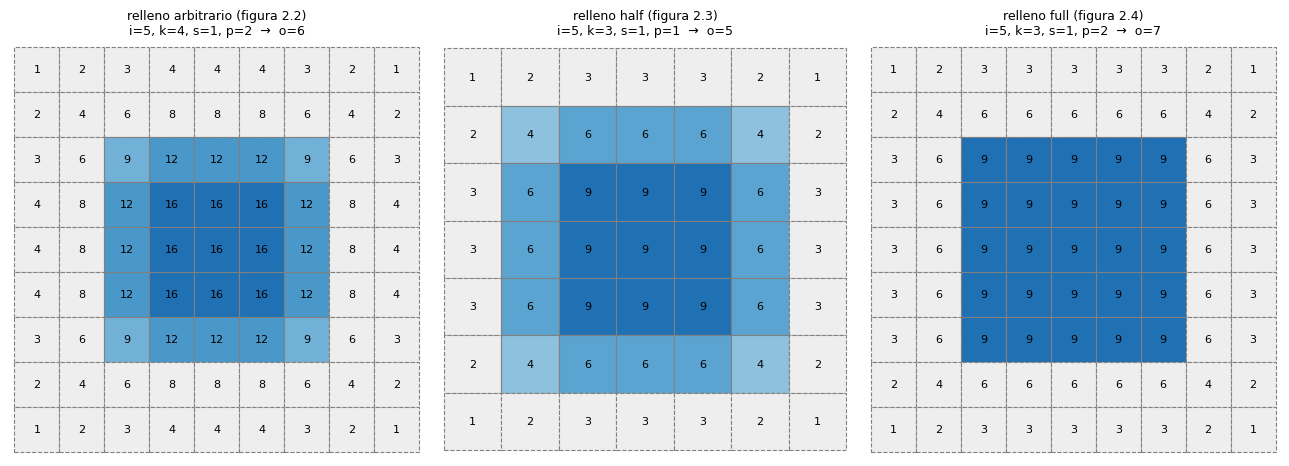

In [11]:
def usos_por_celda(i, k, s=1, p=0):
    """Cuántas posiciones del kernel cubren cada celda de la entrada rellenada."""
    o, n = tam_conv(i, k, s, p), i + 2 * p
    usos = torch.zeros(n, n, dtype=torch.int64)
    for f in range(o):
        for c in range(o):
            usos[f * s:f * s + k, c * s:c * s + k] += 1
    return usos


def dibujar_usos(eje, i, k, s=1, p=0, titulo=""):
    usos, n = usos_por_celda(i, k, s, p), i + 2 * p
    maximo = usos.max().item()
    colores = []
    for fila in range(n):
        colores.append([])
        for col in range(n):
            relleno = fila < p or fila >= p + i or col < p or col >= p + i
            if relleno:
                colores[-1].append(GRIS)
            elif usos[fila, col] == 0:
                colores[-1].append(ROJO)                   # una celda real que el kernel nunca toca
            else:
                colores[-1].append(plt.cm.Blues(0.15 + 0.6 * usos[fila, col].item() / maximo))
    dibujar_grilla(eje, n, p, i, colores)
    for fila in range(n):
        for col in range(n):
            eje.text(col + 0.5, n - 1 - fila + 0.5, str(usos[fila, col].item()), ha="center", va="center", fontsize=8)
    eje.set_title(f"{titulo}\ni={i}, k={k}, s={s}, p={p}  →  o={tam_conv(i, k, s, p)}", fontsize=9)


fig, ejes = plt.subplots(1, 3, figsize=(13, 4.6))
dibujar_usos(ejes[0], 5, 4, p=2, titulo="relleno arbitrario (figura 2.2)")
dibujar_usos(ejes[1], 5, 3, p=1, titulo="relleno half (figura 2.3)")
dibujar_usos(ejes[2], 5, 3, p=2, titulo="relleno full (figura 2.4)")
plt.tight_layout()
plt.show()

Tres cosas que muestra la figura:

- Con relleno *half* (centro), cada celda real queda en el centro del kernel exactamente una vez, y por eso hay tantas salidas como celdas: 5 × 5. Las esquinas reales se usan 4 veces y el centro 9: los bordes de la imagen pesan menos en la salida que el centro.
- Con relleno *full* (derecha), hasta las celdas de relleno de las esquinas se usan una vez: es la posición en que el kernel apenas toca la esquina de la imagen. Por eso la salida crece a 7 × 7.
- Con relleno 2 y un kernel par de 4 × 4 (izquierda), la salida mide 6 × 6, uno más que la entrada. Con un kernel par no hay relleno simétrico que conserve el tamaño: haría falta $p = 1.5$.

¿Qué hace PyTorch con eso? `nn.Conv2d` acepta `padding="same"`, y la documentación aclara que solo funciona con paso 1. Con un kernel par, PyTorch rellena distinto a cada lado, y avisa:

In [12]:
capa_par = nn.Conv2d(1, 1, kernel_size=4, padding="same", bias=False)
x = torch.randn(1, 1, 7, 7)

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    y = capa_par(x)
print("entrada", tuple(x.shape[-2:]), " ->  salida", tuple(y.shape[-2:]))
print("aviso de PyTorch:", str(avisos[0].message).split(" (Triggered")[0])

# relleno asimétrico: 1 arriba y a la izquierda, 2 abajo y a la derecha
asimetrico = F.conv2d(F.pad(x, (1, 2, 1, 2)), capa_par.weight)
print("¿Es relleno 1 antes y 2 después?", torch.allclose(y, asimetrico, atol=1e-6))

try:
    nn.Conv2d(1, 1, kernel_size=3, stride=2, padding="same")
except ValueError as error:
    print("\ncon paso 2:", error)

entrada (7, 7)  ->  salida (7, 7)
aviso de PyTorch: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created
¿Es relleno 1 antes y 2 después? True

con paso 2: padding='same' is not supported for strided convolutions


`padding="same"` resuelve el kernel par rellenando 1 antes y 2 después, algo que la relación 3 del artículo no cubre porque supone relleno simétrico. Para eso PyTorch tiene que crear una copia rellenada de la entrada, que es lo que dice el aviso. En la práctica conviene quedarse con kernels impares, que es lo que hacen las redes del módulo.

## 6. Pasos mayores que 1 (relaciones 5 y 6)

Con paso $s > 1$ y sin relleno, el kernel avanza de a $s$ celdas. Sigue siendo cierto que el tamaño de salida es el número de posiciones: los pasos dados más la posición inicial. Pero puede que el último paso no llegue justo al borde, y por eso aparece la división entera $\lfloor \cdot \rfloor$. Es la **relación 5** ([sección 2.3](https://arxiv.org/abs/1603.07285), p. 15):

$$o = \left\lfloor \frac{i - k}{s} \right\rfloor + 1$$

Y con relleno, aplicando la relación 5 a la entrada rellenada de tamaño $i + 2p$, sale la **relación 6**, el caso general ([sección 2.4](https://arxiv.org/abs/1603.07285), p. 15):

$$o = \left\lfloor \frac{i + 2p - k}{s} \right\rfloor + 1$$

La figura 2.6 del artículo usa $i = 5$, $k = 3$, $s = 2$ y $p = 1$. Las nueve posiciones del kernel, cada una en el lugar de su salida:

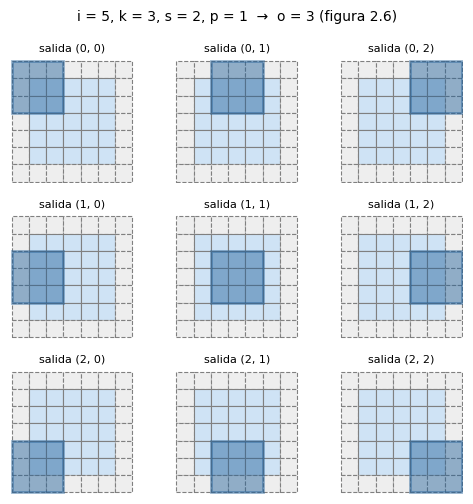

In [13]:
dibujar_posiciones(5, 3, s=2, p=1, titulo="i = 5, k = 3, s = 2, p = 1  →  o = 3 (figura 2.6)")

El kernel salta de a dos celdas, en horizontal y en vertical. La relación 6 es la que vale para todo lo anterior: las relaciones 1 a 5 son casos particulares. La comprobamos en una grilla grande: entradas de 1 a 20, kernels de 1 a 7, rellenos de 0 a 3 y pasos de 1 a 4.

In [14]:
def relacion_6(i, k, s, p):
    return (i + 2 * p - k) // s + 1


grilla = [(i, k, s, p) for i, k, s, p in itertools.product(range(1, 21), range(1, 8), range(1, 5), range(0, 4))
          if k <= i + 2 * p]
coinciden = sum(relacion_6(i, k, s, p) == tam_pytorch(i, k, s, p) for i, k, s, p in grilla)
print(f"relación 6: {len(grilla)} combinaciones, coinciden {coinciden}")

relación 6: 2104 combinaciones, coinciden 2104


Las 2104 combinaciones coinciden. La fórmula de la documentación de `nn.Conv2d` es la relación 15 (la de la sección 11), que con dilatación 1 se reduce a esta.

CS231n escribe la misma cuenta como $(W - F + 2P)/S + 1$, sin la división entera ([*Convolutional Layer*](https://cs231n.github.io/convolutional-networks/#conv)). Sus ejemplos: una entrada de 7 × 7 y un filtro de 3 × 3 dan una salida de 5 × 5 con paso 1 y de 3 × 3 con paso 2.

In [15]:
print("7 x 7, filtro 3, paso 1:", relacion_6(7, 3, 1, 0), "   PyTorch:", tam_pytorch(7, 3, 1, 0))
print("7 x 7, filtro 3, paso 2:", relacion_6(7, 3, 2, 0), "   PyTorch:", tam_pytorch(7, 3, 2, 0))

7 x 7, filtro 3, paso 1: 5    PyTorch: 5
7 x 7, filtro 3, paso 2: 3    PyTorch: 3


El artículo propone otra forma de ver el paso: avanzar de a $s$ es lo mismo que avanzar de a 1 y quedarse con una de cada $s$ salidas ([sección 1.1](https://arxiv.org/abs/1603.07285), figura 1.4, p. 9). En PyTorch eso es tomar `[::2, ::2]` de la salida con paso 1:

In [16]:
x = torch.randn(1, 1, 9, 9)
w = torch.randn(1, 1, 3, 3)
con_paso_2 = F.conv2d(x, w, stride=2)
paso_1_y_submuestreo = F.conv2d(x, w)[..., ::2, ::2]
print(tuple(con_paso_2.shape[-2:]), tuple(paso_1_y_submuestreo.shape[-2:]))
print("¿Iguales?", torch.allclose(con_paso_2, paso_1_y_submuestreo))

(4, 4) (4, 4)
¿Iguales? True


Son iguales. El paso es un **submuestreo**: calcula directamente solo las salidas que se van a conservar. Aquí son 16 salidas contra 49, y en mapas grandes, con paso 2, cerca de una cuarta parte de las cuentas. Es la otra forma de achicar un mapa de características, además del *pooling*; CS231n menciona arquitecturas que descartan el *pooling* y achican usando de vez en cuando un paso mayor en la convolución ([*Pooling Layer*](https://cs231n.github.io/convolutional-networks/#pool), "Getting rid of pooling").

## 7. Lo que se come la división entera

La división entera de la relación 6 tiene dos consecuencias.

**Entradas distintas, la misma salida.** El artículo lo muestra con las figuras 2.6 y 2.7: con $k = 3$, $s = 2$ y $p = 1$, una entrada de 5 y una de 6 dan una salida de 3. En general, si $i + 2p - k$ es múltiplo de $s$, las entradas $i, i + 1, \ldots, i + s - 1$ dan el mismo tamaño de salida; la ambigüedad solo existe con $s > 1$ ([sección 2.4](https://arxiv.org/abs/1603.07285), p. 15). Agrupamos las entradas de 1 a 16 según su salida:

In [17]:
for k, s, p in [(3, 1, 1), (3, 2, 1), (3, 3, 0)]:
    grupos = {}
    for i in range(max(1, k - 2 * p), 17):
        grupos.setdefault(relacion_6(i, k, s, p), []).append(i)
    print(f"k={k}, s={s}, p={p}:", {o: entradas for o, entradas in grupos.items()})

k=3, s=1, p=1: {1: [1], 2: [2], 3: [3], 4: [4], 5: [5], 6: [6], 7: [7], 8: [8], 9: [9], 10: [10], 11: [11], 12: [12], 13: [13], 14: [14], 15: [15], 16: [16]}
k=3, s=2, p=1: {1: [1, 2], 2: [3, 4], 3: [5, 6], 4: [7, 8], 5: [9, 10], 6: [11, 12], 7: [13, 14], 8: [15, 16]}
k=3, s=3, p=0: {1: [3, 4, 5], 2: [6, 7, 8], 3: [9, 10, 11], 4: [12, 13, 14], 5: [15, 16]}


Con paso 1 cada salida viene de una sola entrada. Con paso 2, de dos entradas (5 y 6 dan 3, como en las figuras), y con paso 3, de tres. Para la convolución da lo mismo, pero complica la convolución transpuesta, que tiene que ir de vuelta y no sabe a cuál de esas entradas volver (sección 10).

**Píxeles que nunca se tocan.** Cuando $i + 2p - k$ no es múltiplo de $s$, el kernel no llega al borde derecho ni al de abajo: el último paso lo dejaría afuera. El artículo lo dice al presentar la relación 5: a veces quedan unidades de la entrada sin usar ([sección 2.3](https://arxiv.org/abs/1603.07285), figura 2.7). Para encontrarlas sin dibujar, usamos autograd: una celda de la entrada que no afecta la salida tiene gradiente cero. Dibujamos los usos de las figuras 2.5, 2.6 y 2.7:

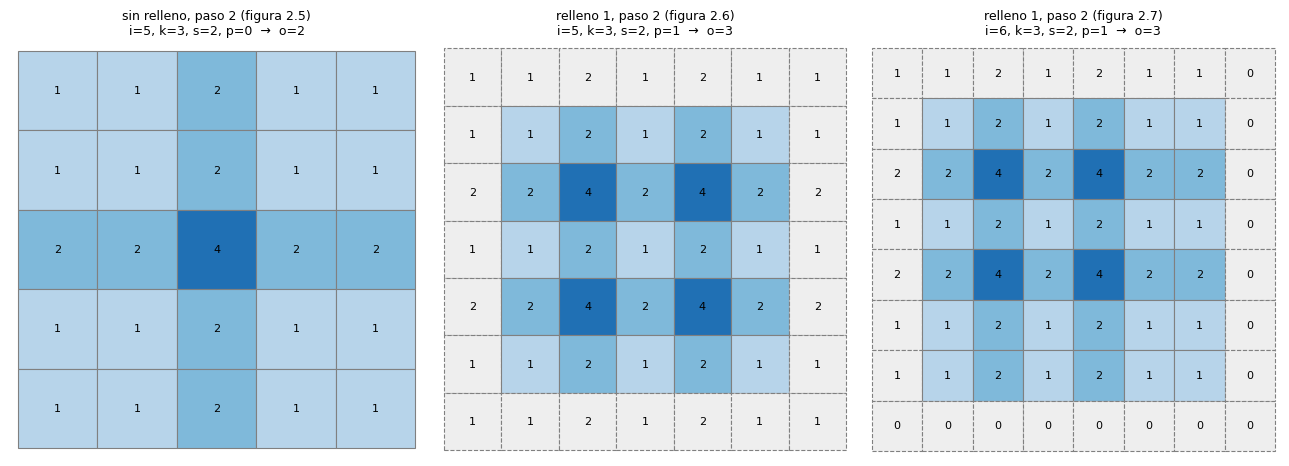

In [18]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4.6))
dibujar_usos(ejes[0], 5, 3, s=2, p=0, titulo="sin relleno, paso 2 (figura 2.5)")
dibujar_usos(ejes[1], 5, 3, s=2, p=1, titulo="relleno 1, paso 2 (figura 2.6)")
dibujar_usos(ejes[2], 6, 3, s=2, p=1, titulo="relleno 1, paso 2 (figura 2.7)")
plt.tight_layout()
plt.show()

En la figura 2.7 (derecha), la última fila y la última columna de la entrada rellenada tienen 0 usos: el kernel nunca llega. Son celdas de relleno, así que no se pierde ningún píxel real. Pero si el borde sobrante cae dentro de la imagen, sí se pierden píxeles. CS231n da el ejemplo de una entrada de 10, un filtro de 3, paso 2 y sin relleno: $(10 - 3)/2 + 1 = 4.5$ no es entero, y dice que una librería podría lanzar un error, rellenar o recortar ([*Convolutional Layer*](https://cs231n.github.io/convolutional-networks/#conv), "Constraints on strides"). Veamos qué elige PyTorch:

In [19]:
def pixeles_sin_usar(i, k, s=1, p=0):
    """Píxeles reales de la entrada cuyo gradiente es cero: el kernel nunca los toca."""
    x = torch.ones(1, 1, i, i, requires_grad=True)
    F.conv2d(x, torch.ones(1, 1, k, k), stride=s, padding=p).sum().backward()
    return (x.grad[0, 0] == 0)


sin_usar = pixeles_sin_usar(10, 3, s=2)
print("salida:", tam_pytorch(10, 3, s=2), "x", tam_pytorch(10, 3, s=2))
print("píxeles sin usar:", sin_usar.sum().item(), "de 100")
print("¿Son la última fila y la última columna?", sin_usar[9].all().item() and sin_usar[:, 9].all().item())

salida: 4 x 4
píxeles sin usar: 19 de 100
¿Son la última fila y la última columna? True


PyTorch no lanza un error: aplica la división entera y **recorta**. La salida mide 4 × 4, y los 19 píxeles de la última fila y la última columna (10 + 10 − 1) no influyen en nada. Si ahí hubiera algo importante, la red no lo vería.

CS231n tiene un ejemplo famoso de esto. La red de Krizhevsky y otros que ganó ImageNet en 2012 recibía imágenes de 227 × 227 y su primera capa usaba filtros de 11, paso 4 y sin relleno: $(227 - 11)/4 + 1 = 55$. Según CS231n, el artículo original dice que las imágenes eran de 224 × 224, y con 224 la cuenta no es entera; los apuntes suponen que hubo 3 píxeles de relleno que el artículo no menciona ([*Convolutional Layer*](https://cs231n.github.io/convolutional-networks/#conv), "Real-world example"). La versión de AlexNet que trae `torchvision` usa relleno 2. Comparamos las tres opciones con 224:

In [20]:
print("primera capa de la AlexNet de torchvision:", torchvision.models.alexnet().features[0])
print()
for p in [0, 2]:
    o = relacion_6(224, 11, 4, p)
    sobra = (224 + 2 * p - 11) % 4
    perdidos = pixeles_sin_usar(224, 11, s=4, p=p).sum().item()
    print(f"224 x 224, relleno {p}: salida {o} x {o}, (i + 2p - k) mod s = {sobra}, píxeles reales sin usar: {perdidos}")
print("\n227 x 227, relleno 0: salida", relacion_6(227, 11, 4, 0), "  (i - k) mod s =", (227 - 11) % 4)

primera capa de la AlexNet de torchvision: Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))

224 x 224, relleno 0: salida 54 x 54, (i + 2p - k) mod s = 1, píxeles reales sin usar: 447
224 x 224, relleno 2: salida 55 x 55, (i + 2p - k) mod s = 1, píxeles reales sin usar: 0

227 x 227, relleno 0: salida 55   (i - k) mod s = 0


Sin relleno, 224 da una salida de 54 y deja sin usar 447 píxeles (la última fila y la última columna, 224 + 224 − 1). Con el relleno 2 de `torchvision`, la salida es 55 y lo que sobra es una fila y una columna de relleno, no de la imagen: no se pierde ningún píxel. Los 3 píxeles extra que supone CS231n son 3 en total, no 3 por lado: 224 + 3 = 227, la cuenta exacta de la última línea. El `padding` numérico de PyTorch rellena igual a ambos lados, así que siempre suma un número par; para sumar 3 habría que rellenar a mano con `F.pad`, 1 de un lado y 2 del otro.

## 8. *Pooling* (relación 7)

El *pooling* desliza una ventana sobre la entrada como la convolución, pero en vez de una combinación lineal aplica otra función: el máximo o el promedio ([sección 1.2](https://arxiv.org/abs/1603.07285), p. 10). El artículo observa que la aritmética de la convolución solo usaba que una función se aplica repetidamente sobre pedazos de la entrada, así que vale igual para el *pooling*. Como el *pooling* no usa relleno de ceros, el caso general es la **relación 7**, que vale para cualquier tipo de *pooling* ([capítulo 3](https://arxiv.org/abs/1603.07285), p. 18):

$$o = \left\lfloor \frac{i - k}{s} \right\rfloor + 1$$

In [21]:
def relacion_7(i, k, s):
    return (i - k) // s + 1


grilla_pool = [(i, k, s) for i, k, s in itertools.product(range(1, 21), range(1, 7), range(1, 5)) if k <= i]
coinciden = sum(
    relacion_7(i, k, s) == F.max_pool2d(torch.zeros(1, 1, i, i), k, stride=s).shape[-1]
    == F.avg_pool2d(torch.zeros(1, 1, i, i), k, stride=s).shape[-1]
    for i, k, s in grilla_pool
)
print(f"relación 7: {len(grilla_pool)} combinaciones, coinciden con MaxPool2d y AvgPool2d en {coinciden}")

relación 7: 420 combinaciones, coinciden con MaxPool2d y AvgPool2d en 420


Coinciden las 420. `nn.MaxPool2d` agrega tres cosas que el artículo no trata, todas en su [documentación](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html):

- el paso por defecto es igual al tamaño de la ventana: `MaxPool2d(2)` es ventana 2 con paso 2, la que usan las redes del módulo;
- acepta relleno, pero con $-\infty$ en vez de ceros (para que el relleno nunca sea el máximo); la documentación no lo dice, pero el error de la celda siguiente muestra que puede ser como mucho de la mitad de la ventana;
- `ceil_mode=True` cambia la división entera hacia abajo por una hacia arriba.

CS231n dice que en la práctica casi solo se ven dos configuraciones: ventana 2 con paso 2, que descarta el 75% de las activaciones, y ventana 3 con paso 2, el *pooling* solapado; y que con 3 y paso 2 una entrada de 32 × 32 necesita relleno ([*Layer Sizing Patterns*](https://cs231n.github.io/convolutional-networks/#layersizepat)). Lo comprobamos:

In [22]:
x = torch.randn(1, 1, 32, 32)
print("ventana 2, paso 2      :", tuple(nn.MaxPool2d(2)(x).shape[-2:]), " -> se conservan", 16 * 16, "de", 32 * 32,
      f"({16 * 16 / (32 * 32):.0%})")
print("ventana 3, paso 2      :", tuple(nn.MaxPool2d(3, stride=2)(x).shape[-2:]), "  ((32 - 3) / 2 + 1 = 15.5 → 15)")
print("  con relleno 1        :", tuple(nn.MaxPool2d(3, stride=2, padding=1)(x).shape[-2:]))
print("  con ceil_mode=True   :", tuple(nn.MaxPool2d(3, stride=2, ceil_mode=True)(x).shape[-2:]))

try:
    nn.MaxPool2d(2, padding=2)(x)
except RuntimeError as error:
    print("\nrelleno 2 con ventana 2:", error)

ventana 2, paso 2      : (16, 16)  -> se conservan 256 de 1024 (25%)
ventana 3, paso 2      : (15, 15)   ((32 - 3) / 2 + 1 = 15.5 → 15)
  con relleno 1        : (16, 16)
  con ceil_mode=True   : (16, 16)

relleno 2 con ventana 2: pad should be at most half of effective kernel size, but got pad=2, kernel_size=2 and dilation=1


Ventana 3 y paso 2 sobre 32 da 15.5, que PyTorch recorta a 15; con relleno 1 o con `ceil_mode=True` llega a 16, la mitad exacta. Y un relleno mayor que media ventana da error.

El artículo abre su capítulo de *pooling* diciendo que estas capas dan invariancia a traslaciones pequeñas de la entrada ([capítulo 3](https://arxiv.org/abs/1603.07285)). Eso no es aritmética y no lo medimos aquí; el notebook `01-arquitectura/01_la_arquitectura_de_una_cnn` lo pone a prueba.

## 9. La convolución como una matriz

El capítulo 4 parte de una observación: la convolución es una transformación lineal, así que se puede escribir como una matriz. Si la entrada y la salida se aplanan en vectores, de izquierda a derecha y de arriba abajo, la convolución de la figura 2.1 ($i = 4$, $k = 3$) es multiplicar por una matriz rala $C$ de 4 × 16 cuyos elementos distintos de cero son los pesos del kernel ([sección 4.1](https://arxiv.org/abs/1603.07285), p. 20). La armamos a mano, para cualquier entrada, paso y relleno: la fila de cada salida tiene el peso del kernel en la columna del píxel de entrada que ese peso multiplica.

In [23]:
def matriz_de_convolucion(w, i, s=1, p=0):
    """Matriz C tal que C @ x.flatten() es la convolución (correlación cruzada) de x con w."""
    k = w.shape[0]
    o = tam_conv(i, k, s, p)
    C = torch.zeros(o * o, i * i)
    for f in range(o):
        for c in range(o):
            for a in range(k):
                for b in range(k):
                    fila, col = f * s + a - p, c * s + b - p      # píxel de entrada bajo el peso w[a, b]
                    if 0 <= fila < i and 0 <= col < i:            # si cae en el relleno, multiplica un cero
                        C[f * o + c, fila * i + col] = w[a, b]
    return C


w = torch.arange(1., 10.).reshape(3, 3)       # pesos 1 a 9, para reconocer dónde queda cada uno
C = matriz_de_convolucion(w, 4)
print(w)
print(C.int())

tensor([[1., 2., 3.],
        [4., 5., 6.],
        [7., 8., 9.]])
tensor([[1, 2, 3, 0, 4, 5, 6, 0, 7, 8, 9, 0, 0, 0, 0, 0],
        [0, 1, 2, 3, 0, 4, 5, 6, 0, 7, 8, 9, 0, 0, 0, 0],
        [0, 0, 0, 0, 1, 2, 3, 0, 4, 5, 6, 0, 7, 8, 9, 0],
        [0, 0, 0, 0, 0, 1, 2, 3, 0, 4, 5, 6, 0, 7, 8, 9]], dtype=torch.int32)


Es la matriz de la sección 4.1 del artículo, con los pesos $w_{0,0}, \ldots, w_{2,2}$ cambiados por 1 a 9. Cada fila es una posición del kernel: los tres pesos de una fila del kernel aparecen seguidos, después un cero (la columna de la entrada que el kernel no cubre en esa posición), y así. Multiplicar por $C$ da lo mismo que `F.conv2d`, para cualquier paso y relleno:

In [24]:
x = torch.randn(4, 4)
print("figura 2.1:", torch.allclose(C @ x.flatten(), F.conv2d(x[None, None], w[None, None]).flatten()))

combinaciones = coinciden = 0
for i, k, s, p in itertools.product(range(3, 9), range(1, 5), range(1, 4), range(0, 3)):
    if k > i + 2 * p:
        continue
    w_azar, x_azar = torch.randn(k, k), torch.randn(i, i)
    C_azar = matriz_de_convolucion(w_azar, i, s, p)
    directa = F.conv2d(x_azar[None, None], w_azar[None, None], stride=s, padding=p).flatten()
    combinaciones += 1
    coinciden += torch.allclose(C_azar @ x_azar.flatten(), directa, atol=1e-5)
print(f"C @ x contra F.conv2d: {combinaciones} combinaciones, coinciden {coinciden}")

figura 2.1: True


C @ x contra F.conv2d: 213 combinaciones, coinciden 213


La matriz hace visibles las dos propiedades que el artículo le atribuye a la convolución: es **rala** (cada salida depende de pocas entradas) y **reutiliza parámetros** (los mismos pesos se aplican en muchos lugares) ([sección 1.1](https://arxiv.org/abs/1603.07285), p. 6). Para una imagen de 32 × 32 con kernel de 3 × 3 y relleno 1:

forma de C: (1024, 1024) = 1048576 elementos
distintos de cero: 8836 (0.84%)
valores distintos entre ellos: 9


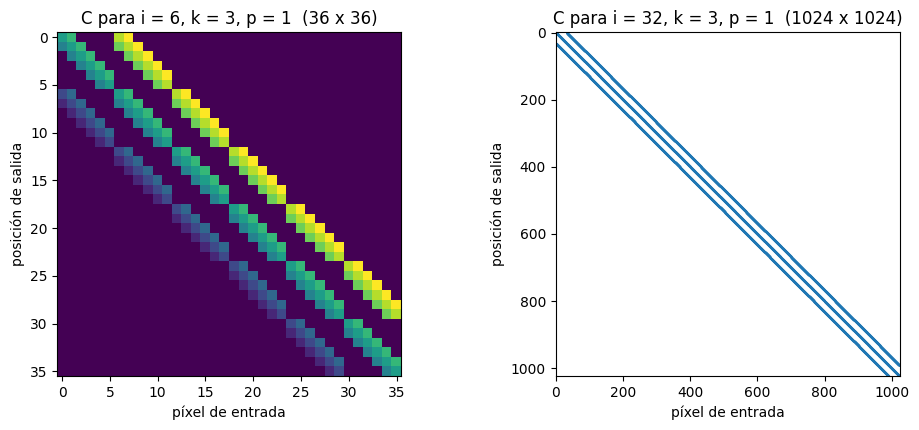

In [25]:
w = torch.randn(3, 3)
C32 = matriz_de_convolucion(w, 32, p=1)
distintos_de_cero = (C32 != 0).sum().item()
print("forma de C:", tuple(C32.shape), "=", C32.numel(), "elementos")
print(f"distintos de cero: {distintos_de_cero} ({distintos_de_cero / C32.numel():.2%})")
print("valores distintos entre ellos:", torch.unique(C32[C32 != 0]).numel())

fig, ejes = plt.subplots(1, 2, figsize=(10, 4.4))
ejes[0].imshow(matriz_de_convolucion(torch.arange(1., 10.).reshape(3, 3), 6, p=1), cmap="viridis")
ejes[0].set_title("C para i = 6, k = 3, p = 1  (36 x 36)")
ejes[1].spy(C32, markersize=0.4)
ejes[1].tick_params(axis="x", top=False, labeltop=False, bottom=True, labelbottom=True)   # spy pone los números arriba
ejes[1].set_title("C para i = 32, k = 3, p = 1  (1024 x 1024)")
for eje in ejes:
    eje.set_xlabel("píxel de entrada")
    eje.set_ylabel("posición de salida")
plt.tight_layout()
plt.show()

Una capa lineal que hiciera lo mismo necesitaría una matriz de 1024 × 1024, más de un millón de pesos. La convolución usa 9: el 99.16% de esa matriz es cero, y los 8.836 valores que no lo son repiten los mismos 9 números. La figura muestra la estructura: bandas diagonales, una por cada fila del kernel. CS231n describe la misma equivalencia: para toda capa convolucional hay una capa densa que calcula lo mismo, con una matriz casi toda en cero y con bloques de pesos iguales ([*Converting FC layers to CONV layers*](https://cs231n.github.io/convolutional-networks/#convert)). PyTorch no arma esa matriz, porque sería un desperdicio de memoria; la usamos solo para entender.

**La pasada hacia atrás.** Con la convolución escrita como $y = Cx$, el gradiente de la pérdida respecto de la entrada es $C^\top$ por el gradiente respecto de la salida. El artículo lo dice así: el error se retropropaga multiplicando por $C^\top$ ([sección 4.1](https://arxiv.org/abs/1603.07285), p. 20). Lo comprobamos contra autograd:

In [26]:
w = torch.arange(1., 10.).reshape(3, 3)
C = matriz_de_convolucion(w, 4)
x = torch.randn(4, 4, requires_grad=True)
gradiente_salida = torch.randn(2, 2)                 # lo que llegaría desde las capas siguientes

F.conv2d(x[None, None], w[None, None]).backward(gradiente_salida[None, None])
print("¿x.grad = C^T @ gradiente?", torch.allclose(x.grad.flatten(), C.T @ gradiente_salida.flatten()))

¿x.grad = C^T @ gradiente? True


`backward()` de una convolución calcula exactamente $C^\top g$. CS231n lo dice con otras palabras: la pasada hacia atrás de una convolución también es una convolución, con los filtros dados vuelta en el espacio ([*Convolutional Layer*](https://cs231n.github.io/convolutional-networks/#conv), "Backpropagation"). Las dos descripciones son la misma; la sección siguiente las junta.

## 10. La convolución transpuesta (relaciones 8 a 14)

A veces se necesita ir en la dirección contraria: de algo con la forma de la salida de una convolución a algo con la forma de su entrada, por ejemplo en el decodificador de un autocodificador, que agranda mapas de características chicos ([capítulo 4](https://arxiv.org/abs/1603.07285), p. 19). La **convolución transpuesta** hace eso intercambiando las dos pasadas: su pasada hacia adelante multiplica por $C^\top$ y su pasada hacia atrás por $C$ ([sección 4.2](https://arxiv.org/abs/1603.07285), p. 20). El mismo kernel define las dos operaciones. Una nota al pie agrega que se puede pensar como el gradiente de una convolución respecto de su entrada, y que así suele implementarse; la documentación de [`nn.ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html) dice lo mismo. Las tres cosas tienen que coincidir: $C^\top y$, `F.conv_transpose2d` y el gradiente de la sección anterior.

In [27]:
y = gradiente_salida                                  # un mapa de 2 x 2
transpuesta = F.conv_transpose2d(y[None, None], w[None, None])[0, 0]

print("forma:", tuple(y.shape), "->", tuple(transpuesta.shape))
print("¿Igual a C^T @ y?           ", torch.allclose(transpuesta.flatten(), C.T @ y.flatten()))
print("¿Igual al gradiente de antes?", torch.allclose(transpuesta, x.grad))

forma: (2, 2) -> (4, 4)
¿Igual a C^T @ y?            True
¿Igual al gradiente de antes? True


Coinciden las tres: de 2 × 2 vuelve a 4 × 4. Ojo con el nombre: no es la inversa de la convolución. Recupera la **forma** de la entrada, no la entrada ([sección 4.3, nota 3](https://arxiv.org/abs/1603.07285), p. 21). Por eso el artículo desaconseja llamarla "deconvolución" ([sección 4.2, nota 1](https://arxiv.org/abs/1603.07285), p. 20), y la documentación de PyTorch aclara que no es una deconvolución de verdad:

In [28]:
x0 = torch.randn(4, 4)
ida_y_vuelta = F.conv_transpose2d(F.conv2d(x0[None, None], w[None, None]), w[None, None])[0, 0]
print("¿Volvimos a x0?", torch.allclose(ida_y_vuelta, x0))
print("error máximo:", (ida_y_vuelta - x0).abs().max().item())

¿Volvimos a x0? False
error máximo: 56.8057975769043


**Con varios canales.** La convolución transpuesta de una `Conv2d` de 2 a 3 canales va de 3 canales a 2, con el mismo tensor de pesos. Por eso `nn.ConvTranspose2d(entradas, salidas)` guarda sus pesos como `[entradas, salidas, alto, ancho]`, la otra permutación de la sección 3: así una `ConvTranspose2d(3, 2, 3)` tiene pesos de la misma forma que una `Conv2d(2, 3, 3)`, y puede usar los suyos.

In [29]:
directa = nn.Conv2d(2, 3, kernel_size=3, bias=False)
transpuesta_capa = nn.ConvTranspose2d(3, 2, kernel_size=3, bias=False)
print("pesos de Conv2d(2, 3)         :", tuple(directa.weight.shape))
print("pesos de ConvTranspose2d(3, 2):", tuple(transpuesta_capa.weight.shape))

with torch.no_grad():
    transpuesta_capa.weight.copy_(directa.weight)

x = torch.randn(1, 2, 6, 6, requires_grad=True)
g = torch.randn(1, 3, 4, 4)
directa(x).backward(g)
print("¿La transpuesta es el gradiente de la directa?", torch.allclose(transpuesta_capa(g), x.grad, atol=1e-6))

pesos de Conv2d(2, 3)         : (3, 2, 3, 3)
pesos de ConvTranspose2d(3, 2): (3, 2, 3, 3)
¿La transpuesta es el gradiente de la directa? True


**Una convolución directa equivalente.** El artículo muestra que toda convolución transpuesta se puede emular con una convolución directa, menos eficiente ([sección 4.2](https://arxiv.org/abs/1603.07285), p. 20). La receta, que arma relación por relación (secciones 4.3 a 4.6), para la transpuesta de una convolución con kernel $k$, paso $s$ y relleno $p$:

1. **estirar** la entrada insertando $s - 1$ ceros entre cada par de unidades (de ahí el nombre "convolución con paso fraccionario");
2. **rellenar** con $k - p - 1$ ceros a cada lado, más $a$ ceros extra abajo y a la derecha, con $a = (i + 2p - k) \bmod s$ (relación 14);
3. convolucionar con paso 1.

Falta un detalle que las relaciones del artículo no necesitan, porque solo tratan tamaños ($k' = k$ dice que el kernel mide lo mismo, no que tenga los mismos valores): la convolución directa equivalente usa el kernel **girado 180°**. No es una particularidad de PyTorch ni de la correlación cruzada: en cualquier convención, multiplicar por $C^\top$ es la misma operación de esa convención con el kernel girado. Es lo que dice CS231n de la pasada hacia atrás: también es una convolución, pero con los filtros dados vuelta en el espacio ([*Convolutional Layer*](https://cs231n.github.io/convolutional-networks/#conv), "Backpropagation"). Lo comprobamos en las dos convenciones.

In [30]:
def estirar_y_rellenar(y, k, s, p, a):
    """La entrada de la convolución directa equivalente a una transpuesta (relaciones 12 a 14)."""
    o = y.shape[-1]
    lado = (o - 1) * s + 1
    estirada = torch.zeros(lado, lado)
    estirada[::s, ::s] = y                                 # s - 1 ceros entre unidades
    r = k - p - 1
    return F.pad(estirada, (r, r + a, r, r + a))           # (izquierda, derecha, arriba, abajo)


combinaciones = coinciden = 0
for i, k, s, p in itertools.product(range(3, 9), range(1, 5), range(1, 4), range(0, 3)):
    if k > i + 2 * p or p > k - 1:                          # con p > k - 1 el relleno sería negativo
        continue
    o, a = relacion_6(i, k, s, p), (i + 2 * p - k) % s
    w_azar, y_azar = torch.randn(k, k), torch.randn(o, o)
    transpuesta = F.conv_transpose2d(y_azar[None, None], w_azar[None, None], stride=s, padding=p, output_padding=a)[0, 0]
    emulada = F.conv2d(estirar_y_rellenar(y_azar, k, s, p, a)[None, None], w_azar.flip(0, 1)[None, None])[0, 0]
    C_azar = matriz_de_convolucion(w_azar, i, s, p)
    combinaciones += 1
    coinciden += (transpuesta.shape == (i, i)
                  and torch.allclose(emulada, transpuesta, atol=1e-5)
                  and torch.allclose((C_azar.T @ y_azar.flatten()).reshape(i, i), transpuesta, atol=1e-5))
print(f"transpuesta = directa sobre la entrada estirada = C^T @ y: {combinaciones} combinaciones, coinciden {coinciden}")


# La otra convención: la convolución de señales, que sí da vuelta el kernel antes de deslizarlo.
def conv_senales(x, w):
    return F.conv2d(x, w.flip(-2, -1))


def conv_senales_transpuesta(y, w, s, p, a):
    # la transpuesta de conv_senales es la de PyTorch con el kernel ya dado vuelta
    return F.conv_transpose2d(y, w.flip(-2, -1), stride=s, padding=p, output_padding=a)


i, k, s, p = 6, 3, 2, 1
o, a = relacion_6(i, k, s, p), (i + 2 * p - k) % s
w_azar, y_azar = torch.randn(k, k), torch.randn(o, o)
z = estirar_y_rellenar(y_azar, k, s, p, a)[None, None]
transpuesta = conv_senales_transpuesta(y_azar[None, None], w_azar[None, None], s, p, a)
print("convolución de señales: ¿su transpuesta es ella misma con el kernel girado?",
      torch.allclose(conv_senales(z, w_azar.flip(0, 1)[None, None]), transpuesta, atol=1e-5))

transpuesta = directa sobre la entrada estirada = C^T @ y: 159 combinaciones, coinciden 159
convolución de señales: ¿su transpuesta es ella misma con el kernel girado? True


Las tres formas coinciden en las 159 combinaciones, y en la convención de señales la transpuesta también es la misma operación con el kernel girado. Dibujamos la entrada estirada y rellenada de las figuras 4.5, 4.6 y 4.7 del artículo. Azul: las unidades de la entrada; blanco: los ceros insertados entre ellas; gris: el relleno; naranja: el relleno extra $a$ de la relación 14.

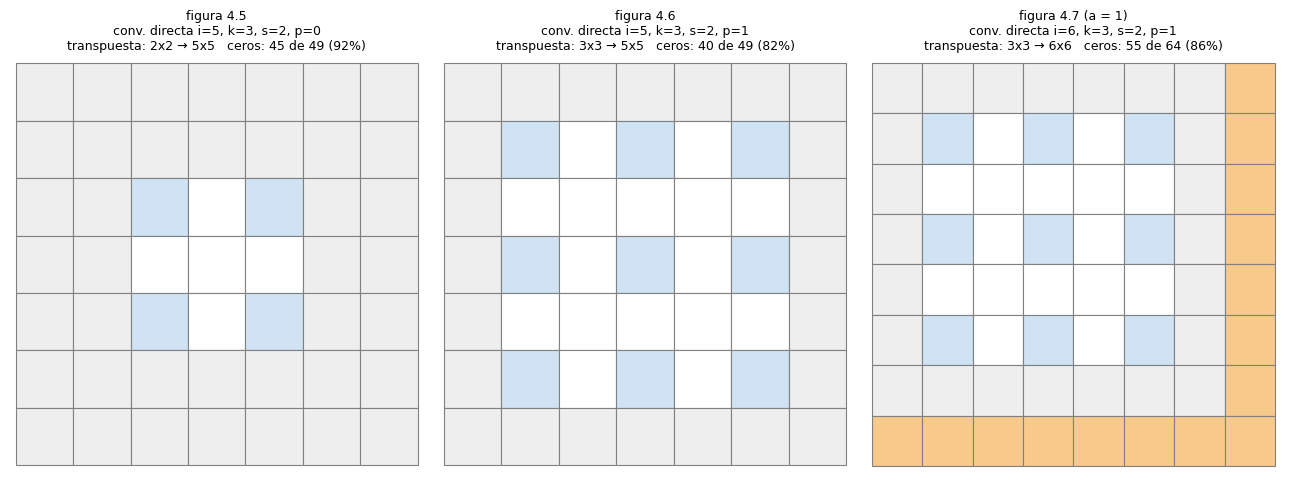

In [31]:
def dibujar_estirada(eje, i, k, s, p, titulo=""):
    o, a = relacion_6(i, k, s, p), (i + 2 * p - k) % s
    lado, r = (o - 1) * s + 1, k - p - 1
    n = lado + 2 * r + a
    colores = []
    for fila in range(n):
        colores.append([])
        for col in range(n):
            if fila >= r + lado + r or col >= r + lado + r:
                colores[-1].append(NARANJA)
            elif r <= fila < r + lado and r <= col < r + lado:
                es_unidad = (fila - r) % s == 0 and (col - r) % s == 0
                colores[-1].append(AZUL if es_unidad else "white")
            else:
                colores[-1].append(GRIS)
    dibujar_grilla(eje, n, 0, n, colores)
    ceros = n * n - o * o
    eje.set_title(f"{titulo}\nconv. directa i={i}, k={k}, s={s}, p={p}\n"
                  f"transpuesta: {o}x{o} → {i}x{i}   ceros: {ceros} de {n * n} ({ceros / (n * n):.0%})", fontsize=9)


fig, ejes = plt.subplots(1, 3, figsize=(13, 5))
dibujar_estirada(ejes[0], 5, 3, 2, 0, "figura 4.5")
dibujar_estirada(ejes[1], 5, 3, 2, 1, "figura 4.6")
dibujar_estirada(ejes[2], 6, 3, 2, 1, "figura 4.7 (a = 1)")
plt.tight_layout()
plt.show()

En los tres casos, más de 80% de lo que recorre el kernel son ceros: en la figura 4.5, una entrada de 2 × 2 queda en medio de una grilla de 7 × 7. Por eso el artículo insiste en que esta forma de verla es solo para entender, y que las implementaciones reales evitan esas multiplicaciones por cero ([secciones 4.3 y 4.5, notas 4 y 5](https://arxiv.org/abs/1603.07285), pp. 21 y 24). La figura 4.7 tiene una fila y una columna naranjas: es el caso de la sección 7, en que la convolución directa dejó sin usar el borde, y la transpuesta tiene que reponerlo para volver a 6 × 6 y no a 5 × 5.

**Las relaciones de tamaño.** Las relaciones 8 a 14 dan el tamaño de salida de la transpuesta, de lo particular a lo general: sin relleno y paso 1, $o' = i' + (k - 1)$ (relación 8); con relleno, $o' = i' + (k - 1) - 2p$ (relación 9, con los casos *half* y *full* en las relaciones 10 y 11); con paso, $o' = s(i' - 1) + k$ (relación 12, que supone sin relleno y que $i - k$ es múltiplo de $s$) y $o' = s(i' - 1) + k - 2p$ (relación 13, que supone que $i + 2p - k$ es múltiplo de $s$), y el caso general, sin esas condiciones ([sección 4.6](https://arxiv.org/abs/1603.07285), p. 26):

$$o' = s(i' - 1) + a + k - 2p, \qquad a = (i + 2p - k) \bmod s$$

donde $i'$ es el tamaño de la entrada de la transpuesta, es decir, la salida $o$ de la convolución directa. El problema es $a$: depende del tamaño $i$ de la entrada **original**, que la transpuesta no conoce. Es la ambigüedad de la sección 7: con paso 2, una salida de 3 pudo venir de 5 o de 6. PyTorch la resuelve con el parámetro `output_padding`, que según la documentación de `nn.ConvTranspose2d` existe para eso: agrega tamaño a un lado de la salida. Su fórmula de tamaño, con dilatación 1, es la relación 14 con `output_padding` en el lugar de $a$. Lo comprobamos en la misma grilla de la sección 6: para cada convolución directa, ¿la transpuesta con `output_padding` $= a$ vuelve al tamaño original? ¿Y sin él?

In [32]:
def tam_transpuesta(i_prima, k, s, p, a):
    """Relación 14."""
    return s * (i_prima - 1) + a + k - 2 * p


con_a = sin_a = sin_error = coincide_formula = a_cero = 0
for i, k, s, p in grilla:
    o, a = relacion_6(i, k, s, p), (i + 2 * p - k) % s
    a_cero += a == 0
    capa_t = nn.ConvTranspose2d(1, 1, k, stride=s, padding=p, output_padding=a)
    vuelta = capa_t(torch.zeros(1, 1, o, o)).shape[-1]
    con_a += vuelta == i
    coincide_formula += vuelta == tam_transpuesta(o, k, s, p, a)
    try:
        sin_a += nn.ConvTranspose2d(1, 1, k, stride=s, padding=p)(torch.zeros(1, 1, o, o)).shape[-1] == i
    except RuntimeError:          # sin output_padding, algunas salidas tendrían tamaño 0 o negativo
        sin_error += 1
print(f"{len(grilla)} convoluciones directas")
print(f"  relación 14 = ConvTranspose2d               : {coincide_formula}")
print(f"  vuelven al tamaño original con output_padding: {con_a}")
print(f"  vuelven al tamaño original sin output_padding: {sin_a}")
print(f"  sin output_padding y con tamaño imposible    : {sin_error}")
print(f"  combinaciones con a = 0                      : {a_cero}")

try:
    nn.ConvTranspose2d(1, 1, 3, stride=2, output_padding=2)(torch.zeros(1, 1, 3, 3))
except RuntimeError as error:
    print("\noutput_padding = paso:", error)

2104 convoluciones directas
  relación 14 = ConvTranspose2d               : 2104
  vuelven al tamaño original con output_padding: 2104
  vuelven al tamaño original sin output_padding: 1108
  sin output_padding y con tamaño imposible    : 29
  combinaciones con a = 0                      : 1108

output_padding = paso: output padding must be smaller than either stride or dilation, but got output_padding_height: 2 output_padding_width: 2 stride_height: 2 stride_width: 2 dilation_height: 1 dilation_width: 1


Con `output_padding` $= a$, las 2104 vuelven al tamaño original. Sin él vuelven 1108, justo las combinaciones con $a = 0$; las otras 996 quedan más chicas que la entrada original, y en 29 de ellas el tamaño calculado es 0 o negativo, y PyTorch da un error. Y `output_padding` tiene que ser menor que el paso, porque $a$ es un resto de dividir por $s$.

En la práctica, esto aparece al armar un decodificador. Una combinación muy usada para duplicar el tamaño es kernel 4, paso 2 y relleno 1: $2(i' - 1) + 4 - 2 = 2i'$ exacto, sin ambigüedad.

In [33]:
x = torch.randn(1, 1, 4, 4)
duplicar = nn.ConvTranspose2d(1, 1, kernel_size=4, stride=2, padding=1)
for _ in range(3):
    print(tuple(x.shape[-2:]), end=" -> ")
    x = duplicar(x)
print(tuple(x.shape[-2:]))

(4, 4) -> (8, 8) -> (16, 16) -> (32, 32)


## 11. Convolución dilatada (relación 15)

La convolución dilatada "infla" el kernel insertando espacios entre sus elementos. El artículo advierte que las implementaciones varían, pero que lo usual es que el factor de dilatación $d$ inserte $d - 1$ espacios, de modo que $d = 1$ es la convolución de siempre ([sección 5.1](https://arxiv.org/abs/1603.07285), p. 28). PyTorch sigue esa convención; más abajo veremos una fuente que no. Un kernel de tamaño $k$ dilatado por $d$ tiene un tamaño efectivo

$$\hat{k} = k + (k - 1)(d - 1)$$

y cambiando $k$ por $\hat{k}$ en la relación 6 sale la **relación 15**, la más general del artículo:

$$o = \left\lfloor \frac{i + 2p - k - (k - 1)(d - 1)}{s} \right\rfloor + 1$$

Es la fórmula que trae la documentación de `nn.Conv2d`, escrita de otra forma. Primero, que dilatar es lo mismo que convolucionar con un kernel más grande lleno de ceros:

In [34]:
w = torch.randn(3, 3)
w_inflado = torch.zeros(5, 5)
w_inflado[::2, ::2] = w                          # k = 3, d = 2  ->  k efectivo = 3 + 2 * 1 = 5
print(w_inflado)

x = torch.randn(1, 1, 7, 7)
dilatada = F.conv2d(x, w[None, None], dilation=2)
print("salida:", tuple(dilatada.shape[-2:]), "  ¿Igual al kernel inflado?",
      torch.allclose(dilatada, F.conv2d(x, w_inflado[None, None]), atol=1e-6))

tensor([[ 2.1123,  0.0000, -0.5548,  0.0000, -1.1430],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [-1.2415,  0.0000,  0.5609,  0.0000,  0.3256],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.1207,  0.0000,  1.3041,  0.0000,  1.9860]])
salida: (3, 3)   ¿Igual al kernel inflado? True


Es el caso de la figura 5.1 del artículo: kernel de 3 × 3, dilatación 2 y entrada de 7 × 7, que dan una salida de 3 × 3. La relación 15 contra `nn.Conv2d`, en una grilla que agrega dilataciones de 1 a 4:

In [35]:
grilla_d = [(i, k, s, p, d) for i, k, s, p, d in itertools.product(range(1, 21), range(1, 6), range(1, 4), range(0, 4), range(1, 5))
            if k + (k - 1) * (d - 1) <= i + 2 * p]
coinciden = sum(tam_conv(i, k, s, p, d) == tam_pytorch(i, k, s, p, d) for i, k, s, p, d in grilla_d)
print(f"relación 15: {len(grilla_d)} combinaciones, coinciden {coinciden}")

relación 15: 4071 combinaciones, coinciden 4071


Coinciden las 4071. La advertencia del artículo sobre las implementaciones importa al leer CS231n: sus apuntes cuentan la dilatación desde 0. Llaman "dilatación 0" a la convolución normal y "dilatación 1" a la que calcula `w[0]*x[0] + w[1]*x[2] + w[2]*x[4]` ([*Convolutional Layer*](https://cs231n.github.io/convolutional-networks/#conv), "Dilated convolutions"). En PyTorch y en el artículo esa es `dilation=2`:

In [36]:
w1 = torch.tensor([2., 3., 5.])
x1 = torch.tensor([1., 10., 100., 1000., 10000.])
a_mano = w1[0] * x1[0] + w1[1] * x1[2] + w1[2] * x1[4]
print("a mano      :", a_mano.item())
print("dilation=2  :", F.conv1d(x1[None, None], w1[None, None], dilation=2).item())

a mano      : 50302.0
dilation=2  : 50302.0


¿Para qué sirve? El artículo dice que la dilatación agranda de forma barata el campo receptivo de cada salida, sin agrandar el kernel, sobre todo al apilar varias capas dilatadas ([sección 5.1](https://arxiv.org/abs/1603.07285)). El campo receptivo es la región de la entrada que influye en una salida, y se puede medir con el mismo truco de la sección 7: los píxeles con gradiente distinto de cero. Tres capas de 3 × 3, sin dilatar y con dilataciones 1, 2 y 4:

In [37]:
def lado_del_campo_receptivo(dilataciones, lado=41):
    capas = [nn.Conv2d(1, 1, 3, padding=d, dilation=d, bias=False) for d in dilataciones]
    for capa in capas:
        nn.init.constant_(capa.weight, 1.0)          # pesos positivos: nada se cancela
    x = torch.zeros(1, 1, lado, lado, requires_grad=True)
    y = x
    for capa in capas:
        y = capa(y)
    y[0, 0, lado // 2, lado // 2].backward()       # la salida del centro
    filas = x.grad[0, 0].abs().sum(dim=1).nonzero()
    return (filas.max() - filas.min() + 1).item()


for dilataciones in [[1, 1, 1], [1, 2, 4]]:
    params = 3 * 9
    print(f"dilataciones {dilataciones}: campo receptivo {lado_del_campo_receptivo(dilataciones)} x "
          f"{lado_del_campo_receptivo(dilataciones)}, con {params} pesos")

dilataciones [1, 1, 1]: campo receptivo 7 x 7, con 27 pesos
dilataciones [1, 2, 4]: campo receptivo 15 x 15, con 27 pesos


Con los mismos 27 pesos, el campo receptivo pasa de 7 × 7 a 15 × 15. Sin dilatar crece de a 2 por capa; con dilataciones que se duplican, crece de forma exponencial con la profundidad. El artículo da como ejemplo concreto a WaveNet (Oord y otros, 2016), un modelo generativo de audio que usa convoluciones dilatadas para que cada muestra nueva dependa de un contexto largo de muestras anteriores ([sección 5.1](https://arxiv.org/abs/1603.07285), p. 28). Los campos receptivos tienen su propio notebook, `05-profundizacion/02_campos_receptivos`.

## 12. Los tamaños de las CNN del módulo

Con las relaciones 6 y 7 se puede calcular, antes de escribir el código, el tamaño de cada capa de una CNN. Hacemos la tabla para las dos redes del módulo: la de Fashion-MNIST (28 × 28, un canal, dos bloques) y la de CIFAR-100 (32 × 32, tres canales, tres bloques). Cada bloque es una convolución de 3 × 3 con relleno 1, una ReLU y un `MaxPool2d(2)`.

In [38]:
def tabla_de_tamanos(lado, canales):
    """Recorre bloques [conv 3x3, relleno 1] + [max pool 2] con las relaciones 6 y 7."""
    print(f"{'capa':28s} {'forma':>16s}")
    print(f"{'entrada':28s} {str((canales[0], lado, lado)):>16s}")
    for c_ent, c_sal in zip(canales[:-1], canales[1:]):
        lado = relacion_6(lado, k=3, s=1, p=1)
        print(f"{f'Conv2d({c_ent}, {c_sal}, 3, padding=1)':28s} {str((c_sal, lado, lado)):>16s}")
        lado = relacion_7(lado, k=2, s=2)
        print(f"{'MaxPool2d(2)':28s} {str((c_sal, lado, lado)):>16s}")
    print(f"{'Flatten':28s} {str((canales[-1] * lado * lado,)):>16s}")
    return canales[-1] * lado * lado


print("Fashion-MNIST\n")
entrada_lineal_fashion = tabla_de_tamanos(28, [1, 32, 64])
print("\nCIFAR-100\n")
entrada_lineal_cifar = tabla_de_tamanos(32, [3, 32, 64, 128])

Fashion-MNIST

capa                                    forma
entrada                           (1, 28, 28)
Conv2d(1, 32, 3, padding=1)      (32, 28, 28)
MaxPool2d(2)                     (32, 14, 14)
Conv2d(32, 64, 3, padding=1)     (64, 14, 14)
MaxPool2d(2)                       (64, 7, 7)
Flatten                               (3136,)

CIFAR-100

capa                                    forma
entrada                           (3, 32, 32)
Conv2d(3, 32, 3, padding=1)      (32, 32, 32)
MaxPool2d(2)                     (32, 16, 16)
Conv2d(32, 64, 3, padding=1)     (64, 16, 16)
MaxPool2d(2)                       (64, 8, 8)
Conv2d(64, 128, 3, padding=1)      (128, 8, 8)
MaxPool2d(2)                      (128, 4, 4)
Flatten                               (2048,)


Las cuentas dan $64 \cdot 7 \cdot 7 = 3136$ y $128 \cdot 4 \cdot 4 = 2048$: el tamaño de entrada de la primera `nn.Linear` en las redes del módulo. Lo confirmamos armando la red de CIFAR, con la cabeza de dos capas lineales del curso (2048 → 512 → 15), y pasándole un lote:

In [39]:
def bloque(c_ent, c_sal):
    return [nn.Conv2d(c_ent, c_sal, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]


red_cifar = nn.Sequential(*bloque(3, 32), *bloque(32, 64), *bloque(64, 128),
                          nn.Flatten(), nn.Linear(2048, 512), nn.ReLU(), nn.Linear(512, 15))
x = torch.randn(8, 3, 32, 32)
for capa in red_cifar:
    x = capa(x)
    if not isinstance(capa, nn.ReLU):
        print(f"{capa.__class__.__name__:10s} {tuple(x.shape)}")

Conv2d     (8, 32, 32, 32)
MaxPool2d  (8, 32, 16, 16)
Conv2d     (8, 64, 16, 16)
MaxPool2d  (8, 64, 8, 8)
Conv2d     (8, 128, 8, 8)
MaxPool2d  (8, 128, 4, 4)
Flatten    (8, 2048)
Linear     (8, 512)
Linear     (8, 15)


Las formas reales calzan con la tabla. Ahora la utilidad de la aritmética: ¿qué pasa si llegan imágenes de otro tamaño? Con 33 × 33 el *pooling* descarta la última fila y columna (la división entera de la sección 7) y todo sigue funcionando. Con 30 × 30, los tamaños quedan 15, 7 y 3, la capa lineal recibe $128 \cdot 3 \cdot 3 = 1152$ números en vez de 2048, y PyTorch reclama:

In [40]:
for lado in [33, 30]:
    tamanos = [lado]
    for _ in range(3):
        tamanos.append(relacion_7(relacion_6(tamanos[-1], 3, 1, 1), 2, 2))
    print(f"{lado} x {lado}: lados {tamanos}  ->  Flatten da {128 * tamanos[-1] ** 2}")
    try:
        red_cifar(torch.randn(8, 3, lado, lado))
        print("   la red funciona\n")
    except RuntimeError as error:
        print("   RuntimeError:", error, "\n")

33 x 33: lados [33, 16, 8, 4]  ->  Flatten da 2048
   la red funciona

30 x 30: lados [30, 15, 7, 3]  ->  Flatten da 1152
   RuntimeError: mat1 and mat2 shapes cannot be multiplied (8x1152 and 2048x512) 



El mensaje `8x1152 and 2048x512` se lee con la tabla en la mano: 8 imágenes, cada una con 1152 números, y una capa que espera 2048 (y devuelve 512). Con la relación 6 y la 7 se sabe de antemano qué tamaños de entrada sirven, sin probar uno por uno (ejercicio 7). El notebook `04-modular-e-inspeccion/01_bloques_inspeccion_y_depuracion` trata cómo depurar este error dentro de una red.

## 13. Resumen

- Con $i$ la entrada, $k$ el kernel, $s$ el paso, $p$ el relleno y $d$ la dilatación, el tamaño de salida de una convolución es $o = \lfloor (i + 2p - k - (k-1)(d-1))/s \rfloor + 1$ (relación 15). Con $d = 1$ es la relación 6, y las relaciones 1 a 5 son casos particulares. Las comprobamos contra PyTorch en miles de combinaciones, sin una sola diferencia.
- Los ejes no interactúan: cada uno se calcula por separado.
- El relleno *half* ($p = \lfloor k/2 \rfloor$ con $k$ impar y paso 1) conserva el tamaño; el *full* ($p = k - 1$) lo agranda en $k - 1$. Con kernels pares, `padding="same"` de PyTorch rellena distinto a cada lado.
- El paso es un submuestreo: equivale a convolucionar con paso 1 y quedarse con una de cada $s$ salidas.
- La división entera tiene dos costos: varias entradas dan la misma salida, y a veces el kernel no llega al último borde. PyTorch recorta en silencio; autograd encuentra los píxeles que no influyen (gradiente cero).
- El *pooling* sigue la relación 7, $o = \lfloor (i - k)/s \rfloor + 1$. En `nn.MaxPool2d` el paso por defecto es la ventana.
- PyTorch calcula una correlación cruzada (no da vuelta el kernel). Las figuras del artículo también.
- Una convolución es una multiplicación por una matriz rala $C$ con los pesos repetidos. Su gradiente respecto de la entrada es $C^\top$.
- La convolución transpuesta multiplica por $C^\top$: es el gradiente de una convolución, recupera la forma pero no los valores, y equivale a una convolución directa sobre la entrada estirada con ceros, con el kernel dado vuelta. Su tamaño es $s(i' - 1) + a + k - 2p$ (relación 14), y `output_padding` fija el $a$ que la división entera borró.
- La dilatación agranda el kernel efectivo a $k + (k-1)(d-1)$ sin agregar pesos, y apilada hace crecer rápido el campo receptivo.
- Con las relaciones 6 y 7 se calcula la tabla de tamaños de una CNN antes de escribirla, y se entiende el error de formas cuando la entrada no es la esperada.

## Ejercicios

1. Antes de ejecutar: ¿qué tamaño de salida dan una entrada de 28, kernel 5, paso 1 y relleno 0? ¿Y una de 224 con kernel 7, paso 2 y relleno 3 (la primera capa de las ResNet)? Compruébalo con `tam_pytorch`.
2. Con kernel 5 y paso 2, ¿qué relleno hace que una entrada de 32 dé una salida de exactamente 16? ¿Y una entrada de 33? Usa la relación 6 para responder y compruébalo con `nn.Conv2d`.
3. Arma $C$ con `matriz_de_convolucion` para la figura 2.6 ($i = 5$, $k = 3$, $s = 2$, $p = 1$). ¿Qué forma tiene? ¿Cuántos elementos distintos de cero tiene cada fila, y por qué no son siempre 9?
4. Escribe la relación 6 para una dimensión y compruébala contra `nn.Conv1d` en una grilla como la de la sección 6. ¿Hace falta cambiar algo?
5. Un decodificador debe llevar un mapa de 7 × 7 a 28 × 28 con dos `ConvTranspose2d`. Elige kernel, paso, relleno y `output_padding` con la relación 14, y compruébalo.
6. Apila cuatro convoluciones de 3 × 3 con dilataciones 1, 2, 4 y 8 y mide su campo receptivo con `lado_del_campo_receptivo`. ¿Cuánto mide con cinco capas, la última con dilatación 16? ¿Qué fórmula sigue?
7. ¿Para qué lados de entrada entre 20 y 64 funciona `red_cifar` sin error? Predícelo con las relaciones 6 y 7 y compruébalo.

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026.

**Del material del curso**

- **V. Dumoulin y F. Visin**, [*A guide to convolution arithmetic for deep learning*](https://arxiv.org/abs/1603.07285) (arXiv 1603.07285, versión 2, del 11 de enero de 2018 según el sello de arXiv). Las páginas son las del PDF de arXiv. Las animaciones de sus figuras están en [github.com/vdumoulin/conv_arithmetic](https://github.com/vdumoulin/conv_arithmetic).
  - Capítulo 1, p. 5: "A convolutional layer's output shape is affected by the shape of its input as well as the choice of kernel shape, zero padding and strides, and the relationship between these properties is not trivial to infer. This contrasts with fully-connected layers, whose output size is independent of the input size."
  - Sección 1.1, pp. 6–8: "A discrete convolution is a linear transformation that preserves this notion of ordering. It is sparse (only a few input units contribute to a given output unit) and reuses parameters (the same weights are applied to multiple locations in the input)"; "At each location, the product between each element of the kernel and the input element it overlaps is computed and the results are summed up to obtain the output in the current location"; "If there are multiple input feature maps, the kernel will have to be 3-dimensional – or, equivalently each one of the feature maps will be convolved with a distinct kernel – and the resulting feature maps will be summed up elementwise to produce the output feature map"; "The collection of kernels defining a discrete convolution has a shape corresponding to some permutation of (n, m, k1, . . . , kN)"; nota 2: "While there is a distinction between convolution and cross-correlation from a signal processing perspective, the two become interchangeable when the kernel is learned"; figura 1.4: "Instead of translating the 3 × 3 kernel by increments of s = 2 (left), the kernel is translated by increments of 1 and only one in s = 2 output elements is retained (right)." Las figuras 1.1, 1.2, 1.5 y 1.6 (pp. 7 y 11) son las que reproducimos en la sección 2.
  - Sección 1.2, p. 10: "Pooling works by sliding a window across the input and feeding the content of the window to a pooling function. In some sense, pooling works very much like a discrete convolution, but replaces the linear combination described by the kernel with some other function."
  - Capítulo 2, p. 12: "they don't interact across axes, i.e., the choice of kernel size, stride and zero padding along axis j only affects the output size of axis j."
  - Relaciones 1 a 4 (secciones 2.1 a 2.2.2, p. 13): "Relationship 1. For any i and k, and for s = 1 and p = 0, o = (i − k) + 1"; "Relationship 2. For any i, k and p, and for s = 1, o = (i − k) + 2p + 1"; "Relationship 3. For any i and for k odd (k = 2n + 1, n ∈ N), s = 1 and p = ⌊k/2⌋ = n, o = i"; "Relationship 4. For any i and k, and for p = k − 1 and s = 1, o = i + (k − 1)"; y, p. 15: "This is sometimes referred to as full padding, because in this setting every possible partial or complete superimposition of the kernel on the input feature map is taken into account."
  - Relaciones 5 y 6 (secciones 2.3 y 2.4, p. 15): "Relationship 5. For any i, k and s, and for p = 0, o = ⌊(i − k)/s⌋ + 1. The floor function accounts for the fact that sometimes the last possible step does not coincide with the kernel reaching the end of the input, i.e., some input units are left out"; "Relationship 6. For any i, k, p and s, o = ⌊(i + 2p − k)/s⌋ + 1"; "if i + 2p − k is a multiple of s, then any input size j = i + a, a ∈ {0, . . . , s − 1} will produce the same output size. Note that this ambiguity applies only for s > 1."
  - Capítulo 3, p. 18: "In a neural network, pooling layers provide invariance to small translations of the input"; "Since pooling does not involve zero padding, the relationship describing the general case is as follows: Relationship 7. For any i, k and s, o = ⌊(i − k)/s⌋ + 1. This relationship holds for any type of pooling."
  - Capítulo 4, p. 19: "one might use such a transformation as the decoding layer of a convolutional autoencoder or to project feature maps to a higher-dimensional space."
  - Sección 4.1, p. 20: "the convolution could be represented as a sparse matrix C where the non-zero elements are the elements wi,j of the kernel"; "the error is backpropagated by multiplying the loss with CT."
  - Sección 4.2, p. 20: "Transposed convolutions – also called fractionally strided convolutions or deconvolutions – work by swapping the forward and backward passes of a convolution"; "it also defines a transposed convolution whose forward and backward passes are computed by multiplying with CT and (CT)T = C respectively"; "it is always possible to emulate a transposed convolution with a direct convolution"; nota 1: "we advocate against it on the grounds that a deconvolution is mathematically defined as the inverse of a convolution, which is different from a transposed convolution"; nota 2: "The transposed convolution operation can be thought of as the gradient of some convolution with respect to its input, which is usually how transposed convolutions are implemented in practice."
  - Sección 4.3, p. 21, nota 3: "the transposed convolution does not guarantee to recover the input itself, as it is not defined as the inverse of the convolution, but rather just returns a feature map that has the same width and height"; nota 4: "it is inefficient, and software implementations will normally not perform the useless zero multiplications."
  - Relaciones 8 a 14 (secciones 4.3 a 4.6, pp. 22–26): "Relationship 8. A convolution described by s = 1, p = 0 and k has an associated transposed convolution described by k′ = k, s′ = s and p′ = k − 1 and its output size is o′ = i′ + (k − 1)"; "Relationship 9. ... p′ = k − p − 1 and its output size is o′ = i′ + (k − 1) − 2p"; relación 12: "where ĩ′ is the size of the stretched input obtained by adding s − 1 zeros between each input unit, and its output size is o′ = s(i′ − 1) + k"; relación 13: "o′ = s(i′ − 1) + k − 2p"; "Relationship 14. A convolution described by k, s and p has an associated transposed convolution described by a, ĩ′, k′ = k, s′ = 1 and p′ = k − p − 1, where ĩ′ is the size of the stretched input obtained by adding s − 1 zeros between each input unit, and a = (i + 2p − k) mod s represents the number of zeros added to the bottom and right edges of the input, and its output size is o′ = s(i′ − 1) + a + k − 2p." Sección 4.5, nota 5 (p. 24): "real-world implementations avoid useless multiplications by zero."
  - Sección 5.1, p. 28: "Dilated convolutions “inflate” the kernel by inserting spaces between the kernel elements"; "Implementations may vary, but there are usually d−1 spaces inserted between kernel elements such that d = 1 corresponds to a regular convolution"; "Dilated convolutions are used to cheaply increase the receptive field of output units without increasing the kernel size, which is especially effective when multiple dilated convolutions are stacked one after another"; "For a concrete example, see Oord et al. (2016), in which the proposed WaveNet model implements an autoregressive generative model for raw audio which uses dilated convolutions to condition new audio frames on a large context of past audio frames"; "A kernel of size k dilated by a factor d has an effective size k̂ = k + (k − 1)(d − 1)"; "Relationship 15. For any i, k, p and s, and for a dilation rate d, o = ⌊(i + 2p − k − (k − 1)(d − 1))/s⌋ + 1."
- **CS231n**, [*Convolutional Neural Networks: Architectures, Convolution / Pooling Layers*](https://cs231n.github.io/convolutional-networks/) (Stanford):
  - [*Convolutional Layer*](https://cs231n.github.io/convolutional-networks/#conv): "the correct formula for calculating how many neurons “fit” is given by (W − F + 2P)/S + 1. For example for a 7x7 input and a 3x3 filter with stride 1 and pad 0 we would get a 5x5 output. With stride 2 we would get a 3x3 output"; "Use of zero-padding": "setting zero padding to be P = (F − 1)/2 when the stride is S = 1 ensures that the input volume and output volume will have the same size spatially"; "Constraints on strides": "when the input has size W = 10, no zero-padding is used P = 0, and the filter size is F = 3, then it would be impossible to use stride S = 2, since (W − F + 2P)/S + 1 = (10 − 3 + 0) / 2 + 1 = 4.5 ... a ConvNet library could throw an exception or zero pad the rest to make it fit, or crop the input to make it fit, or something"; "Real-world example": "The Krizhevsky et al. architecture that won the ImageNet challenge in 2012 accepted images of size [227x227x3]. On the first Convolutional Layer, it used neurons with receptive field size F = 11, stride S = 4 and no zero padding P = 0. Since (227 − 11)/4 + 1 = 55 ... if you read the actual paper it claims that the input images were 224x224, which is surely incorrect because (224 − 11)/4 + 1 is quite clearly not an integer ... My own best guess is that Alex used zero-padding of 3 extra pixels that he does not mention in the paper"; "Backpropagation": "The backward pass for a convolution operation (for both the data and the weights) is also a convolution (but with spatially-flipped filters)"; "Dilated convolutions": "in one dimension a filter w of size 3 would compute over input x the following: w[0]*x[0] + w[1]*x[1] + w[2]*x[2]. This is dilation of 0. For dilation 1 the filter would instead compute w[0]*x[0] + w[1]*x[2] + w[2]*x[4]."
  - [*Pooling Layer*](https://cs231n.github.io/convolutional-networks/#pool): "there are only two commonly seen variations of the max pooling layer found in practice: A pooling layer with F = 3, S = 2 (also called overlapping pooling), and more commonly F = 2, S = 2"; "Getting rid of pooling": "To reduce the size of the representation they suggest using larger stride in CONV layer once in a while."
  - [*Converting FC layers to CONV layers*](https://cs231n.github.io/convolutional-networks/#convert): "For any CONV layer there is an FC layer that implements the same forward function. The weight matrix would be a large matrix that is mostly zero except for at certain blocks (due to local connectivity) where the weights in many of the blocks are equal (due to parameter sharing)."
  - [*Layer Sizing Patterns*](https://cs231n.github.io/convolutional-networks/#layersizepat): "The most common setting is to use max-pooling with 2x2 receptive fields (i.e. F = 2), and with a stride of 2 (i.e. S = 2). Note that this discards exactly 75% of the activations in an input volume"; "a 32x32x3 layer would require zero padding to be used with a max-pooling layer with 3x3 receptive field and stride 2."

**Documentación de PyTorch** (versión estable; el notebook se ejecutó con la versión que imprime la sección 1)

- [`torch.nn.Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html): "where ⋆ is the valid 2D cross-correlation operator"; "padding='valid' is the same as no padding. padding='same' pads the input so the output has the shape as the input. However, this mode doesn’t support any stride values other than 1"; la forma de los pesos, "(out_channels, in_channels/groups, kernel_size[0], kernel_size[1])"; y la fórmula de la sección *Shape*, $H_{out} = \lfloor (H_{in} + 2 \times \text{padding} - \text{dilation} \times (\text{kernel\_size} - 1) - 1)/\text{stride} + 1 \rfloor$, que es la relación 15.
- [`torch.nn.ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html): "This module can be seen as the gradient of Conv2d with respect to its input. It is also known as a fractionally-strided convolution or a deconvolution (although it is not an actual deconvolution operation as it does not compute a true inverse of convolution)"; "when stride > 1, Conv2d maps multiple input shapes to the same output shape. output_padding is provided to resolve this ambiguity by effectively increasing the calculated output shape on one side"; la forma de los pesos, "(in_channels, out_channels/groups, kernel_size[0], kernel_size[1])"; y $H_{out} = (H_{in} - 1) \times \text{stride} - 2 \times \text{padding} + \text{dilation} \times (\text{kernel\_size} - 1) + \text{output\_padding} + 1$.
- [`torch.nn.MaxPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html): "stride ... Default value is kernel_size"; "If padding is non-zero, then the input is implicitly padded with negative infinity on both sides"; "ceil_mode ... when True, will use ceil instead of floor to compute the output shape."

**Lo que no viene de una fuente** son los números de este notebook (las grillas de combinaciones, las matrices, los píxeles sin usar, los porcentajes de ceros y los campos receptivos): todos salen de las celdas de código. También son nuestros los dibujos de posiciones y usos, la comprobación de que el relleno 2 de la AlexNet de `torchvision` no descarta píxeles reales, y la comprobación numérica, en las dos convenciones, de que la convolución directa equivalente a una transpuesta usa el kernel girado 180° (la razón es la frase de CS231n sobre la pasada hacia atrás).